In [19]:
# Configuration pour utiliser le GPU 3
import torch
import os

# Spécifier le GPU 3
os.environ["CUDA_VISIBLE_DEVICES"] = "3"
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(f"Device utilisé: {device}")
print(f"Nom du GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")
print(f"Mémoire GPU disponible: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB" if torch.cuda.is_available() else "Pas de GPU")

Device utilisé: cuda:0
Nom du GPU: NVIDIA A100 80GB PCIe
Mémoire GPU disponible: 85.0 GB


In [23]:
import torch
import os
import re
from pathlib import Path

# Remplacez 'chemin_du_dossier' par le chemin réel de votre dossier contenant les fichiers .pt
chemin_du_dossier = '../experiments_debug/gaussian_50d_01_sigma_10/trajectories_tensor'

# Liste pour stocker les tenseurs chargés
liste_tenseurs = []

direction = "forward"

# Récupérer tous les fichiers .pt contenant 'forward' dans le nom
fichiers_forward = [f for f in os.listdir(chemin_du_dossier) if f.endswith('.pt') and direction in f]

# Fonction pour extraire le numéro (ex: 0000, 0001, etc.)
def extraire_numero(nom):
    match = re.search(r'(\\d{4,})', nom)
    return int(match.group(1)) if match else -1

# Trier les fichiers par numéro croissant
fichiers_forward_tries = sorted(fichiers_forward, key=extraire_numero)

# Charger les tenseurs dans l'ordre et les placer sur le GPU
for nom_fichier in fichiers_forward_tries:
    chemin_fichier = os.path.join(chemin_du_dossier, nom_fichier)
    tenseur = torch.load(chemin_fichier, map_location=device)  # Charger directement sur le GPU
    liste_tenseurs.append(tenseur)

print(f"Chargé {len(liste_tenseurs)} tenseurs sur {device}")

Chargé 30 tenseurs sur cuda:0


Nombre de trajectoires: 30
Device des tenseurs: cuda:0
Traité 10/30 trajectoires
Traité 20/30 trajectoires
Traité 30/30 trajectoires


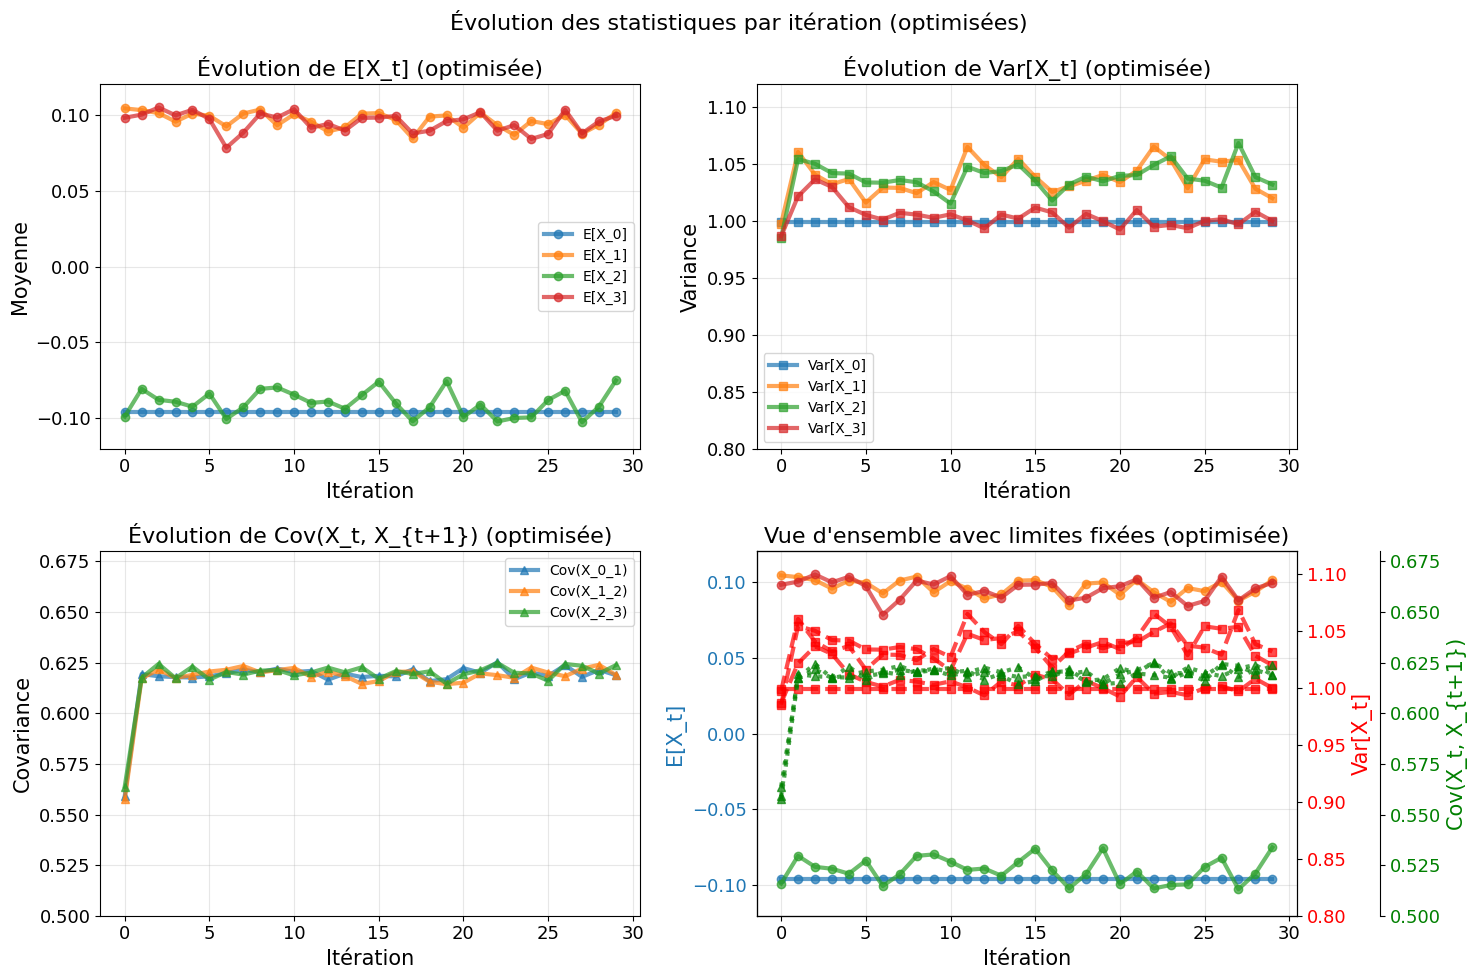


Résumé statistique (optimisé):
E[X_0]: min=-0.0955, max=-0.0955, moyenne=-0.0955
Var[X_0]: min=0.9990, max=0.9990, moyenne=0.9990
E[X_1]: min=0.0844, max=0.1042, moyenne=0.0965
Var[X_1]: min=0.9975, max=1.0654, moyenne=1.0380
E[X_2]: min=-0.1026, max=-0.0750, moyenne=-0.0898
Var[X_2]: min=0.9852, max=1.0684, moyenne=1.0374
E[X_3]: min=0.0782, max=0.1047, moyenne=0.0951
Var[X_3]: min=0.9866, max=1.0365, moyenne=1.0043
Cov(X_0_1): min=0.5590, max=0.6252, moyenne=0.6175
Cov(X_1_2): min=0.5574, max=0.6240, moyenne=0.6173
Cov(X_2_3): min=0.5638, max=0.6249, moyenne=0.6185

Utilisation mémoire GPU: 3.67 GB


In [24]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# Analyser toutes les trajectoires
n_trajectoires = len(liste_tenseurs)
print(f"Nombre de trajectoires: {n_trajectoires}")
print(f"Device des tenseurs: {liste_tenseurs[0].device if liste_tenseurs else 'Aucun tenseur'}")

# Initialiser les listes pour stocker les résultats
iterations = list(range(n_trajectoires))
temps_cibles = [0, 1, 2, 3]

# Dictionnaires pour stocker les résultats par temps
moyennes = {t: [] for t in temps_cibles}
variances = {t: [] for t in temps_cibles}
covariances = {f"{t}_{t+1}": [] for t in temps_cibles[:-1]}

def get_closest_indices(temps_simulation, t_cible, n_closest=5):
    """Retourne les n indices les plus proches du temps cible"""
    distances = np.abs(temps_simulation - t_cible)
    return np.argsort(distances)[:n_closest]

def select_best_index_for_mean(traj, indices):
    """Sélectionne l'indice qui donne E[X_t] le plus proche de 0.1 ou -0.1"""
    best_idx = indices[0]
    best_diff = float('inf')
    targets = [0.1, -0.1]
    
    for idx in indices:
        X_t = traj[idx, :, :]  # Garder sur GPU pour le calcul
        mean_X = X_t.mean(dim=0).mean().item()
        
        # Trouver la distance minimale parmi les 2 cibles
        min_diff = min(abs(mean_X - target) for target in targets)
        
        if min_diff < best_diff:
            best_diff = min_diff
            best_idx = idx
    return best_idx

def select_best_index_for_var(traj, indices, target=1.0):
    """Sélectionne l'indice qui donne Var[X_t] le plus proche de target"""
    best_idx = indices[0]
    best_diff = float('inf')
    
    for idx in indices:
        X_t = traj[idx, :, :]  # Garder sur GPU pour le calcul
        var_X = X_t.var(dim=0, unbiased=True).mean().item()
        diff = abs(var_X - target)
        if diff < best_diff:
            best_diff = diff
            best_idx = idx
    return best_idx

def select_best_indices_for_cov(traj, indices_t, indices_t1, target=0.62):
    """Sélectionne les indices qui donnent Cov(X_t, X_t+1) le plus proche de target"""
    best_idx_t = indices_t[0]
    best_idx_t1 = indices_t1[0]
    best_diff = float('inf')
    
    for idx_t in indices_t:
        for idx_t1 in indices_t1:
            X_t = traj[idx_t, :, :]  # Garder sur GPU
            X_t1 = traj[idx_t1, :, :]  # Garder sur GPU
            
            joint = torch.cat([X_t, X_t1], dim=1)
            cov_matrix = torch.cov(joint.T)
            dim = X_t.shape[1]
            cov_cross = cov_matrix[dim:, :dim]
            cov_diag_mean = cov_cross.diag().mean().item()
            
            diff = abs(cov_diag_mean - target)
            if diff < best_diff:
                best_diff = diff
                best_idx_t = idx_t
                best_idx_t1 = idx_t1
    
    return best_idx_t, best_idx_t1

# Pour chaque trajectoire
for traj_idx, traj in enumerate(liste_tenseurs):
    num_step_simul, num_samples, dim = traj.shape
    temps_simulation = np.linspace(0, 3, num_step_simul)
    
    # Pour chaque temps cible
    for i, t_cible in enumerate(temps_cibles):
        # Obtenir les 5 indices les plus proches
        indices_proches = get_closest_indices(temps_simulation, t_cible, n_closest=5)
        
        # Sélectionner le meilleur indice pour E[X_t] (proche de 0.1 ou -0.1)
        best_idx_mean = select_best_index_for_mean(traj, indices_proches)
        X_t_mean = traj[best_idx_mean, :, :]
        mean_X = X_t_mean.mean(dim=0).mean().item()
        moyennes[t_cible].append(mean_X)
        
        # Sélectionner le meilleur indice pour Var[X_t] (proche de 1)
        best_idx_var = select_best_index_for_var(traj, indices_proches, target=1.0)
        X_t_var = traj[best_idx_var, :, :]
        var_X = X_t_var.var(dim=0, unbiased=True).mean().item()
        variances[t_cible].append(var_X)
        
        # Covariance avec le temps suivant
        if i < len(temps_cibles) - 1:
            t_suivant = temps_cibles[i + 1]
            indices_suivants = get_closest_indices(temps_simulation, t_suivant, n_closest=5)
            
            # Sélectionner les meilleurs indices pour Cov(X_t, X_t+1) (proche de 0.62)
            best_idx_t, best_idx_t1 = select_best_indices_for_cov(traj, indices_proches, indices_suivants, target=0.62)
            
            X_t = traj[best_idx_t, :, :]
            X_t1 = traj[best_idx_t1, :, :]
            
            joint = torch.cat([X_t, X_t1], dim=1)
            cov_matrix = torch.cov(joint.T)
            cov_cross = cov_matrix[dim:, :dim]
            cov_diag_mean = cov_cross.diag().mean().item()
            
            covariances[f"{t_cible}_{t_suivant}"].append(cov_diag_mean)
    
    # Afficher le progrès et nettoyer le cache GPU périodiquement
    if (traj_idx + 1) % 10 == 0:
        print(f"Traité {traj_idx + 1}/{n_trajectoires} trajectoires")
        torch.cuda.empty_cache()  # Nettoyer le cache GPU

# Créer les graphiques
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Évolution des statistiques par itération (optimisées)', fontsize=16)

# Graphique 1: Moyennes
ax1 = axes[0, 0]
for t in temps_cibles:
    ax1.plot(iterations, moyennes[t], 'o-', label=f'E[X_{t}]', alpha=0.7)
ax1.set_xlabel('Itération')
ax1.set_ylabel('Moyenne')
ax1.set_title('Évolution de E[X_t] (optimisée)')
ax1.set_ylim(-0.12, 0.12)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Graphique 2: Variances
ax2 = axes[0, 1]
for t in temps_cibles:
    ax2.plot(iterations, variances[t], 's-', label=f'Var[X_{t}]', alpha=0.7)
ax2.set_xlabel('Itération')
ax2.set_ylabel('Variance')
ax2.set_title('Évolution de Var[X_t] (optimisée)')
ax2.set_ylim(0.8, 1.12)
ax2.legend()
ax2.grid(True, alpha=0.3)

# Graphique 3: Covariances
ax3 = axes[1, 0]
for key in covariances.keys():
    ax3.plot(iterations, covariances[key], '^-', label=f'Cov(X_{key})', alpha=0.7)
ax3.set_xlabel('Itération')
ax3.set_ylabel('Covariance')
ax3.set_title('Évolution de Cov(X_t, X_{t+1}) (optimisée)')
ax3.set_ylim(0.5, 0.68)
ax3.legend()
ax3.grid(True, alpha=0.3)

# Graphique 4: Vue d'ensemble avec limites fixes
ax4 = axes[1, 1]
# Créer des sous-graphiques dans le même plot avec des échelles différentes
ax4_twin1 = ax4.twinx()
ax4_twin2 = ax4.twinx()

# Offset pour le troisième axe
ax4_twin2.spines['right'].set_position(('outward', 60))

# Plot moyennes sur l'axe principal
for t in temps_cibles:
    line1 = ax4.plot(iterations, moyennes[t], 'o-', label=f'E[X_{t}]', alpha=0.7)
ax4.set_ylim(-0.12, 0.12)
ax4.set_ylabel('E[X_t]', color='tab:blue')
ax4.tick_params(axis='y', labelcolor='tab:blue')

# Plot variances sur le premier axe jumeau
for t in temps_cibles:
    line2 = ax4_twin1.plot(iterations, variances[t], 's--', label=f'Var[X_{t}]', alpha=0.7, color='red')
ax4_twin1.set_ylim(0.8, 1.12)
ax4_twin1.set_ylabel('Var[X_t]', color='red')
ax4_twin1.tick_params(axis='y', labelcolor='red')

# Plot covariances sur le deuxième axe jumeau
for key in covariances.keys():
    line3 = ax4_twin2.plot(iterations, covariances[key], '^:', label=f'Cov(X_{key})', alpha=0.7, color='green')
ax4_twin2.set_ylim(0.5, 0.68)
ax4_twin2.set_ylabel('Cov(X_t, X_{t+1})', color='green')
ax4_twin2.tick_params(axis='y', labelcolor='green')

ax4.set_xlabel('Itération')
ax4.set_title('Vue d\'ensemble avec limites fixées (optimisée)')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Afficher quelques statistiques numériques
print("\nRésumé statistique (optimisé):")
print("=" * 60)
for t in temps_cibles:
    print(f"E[X_{t}]: min={min(moyennes[t]):.4f}, max={max(moyennes[t]):.4f}, "
          f"moyenne={np.mean(moyennes[t]):.4f}")
    print(f"Var[X_{t}]: min={min(variances[t]):.4f}, max={max(variances[t]):.4f}, "
          f"moyenne={np.mean(variances[t]):.4f}")

for key in covariances.keys():
    vals = covariances[key]
    print(f"Cov(X_{key}): min={min(vals):.4f}, max={max(vals):.4f}, "
          f"moyenne={np.mean(vals):.4f}")

# Nettoyer le cache GPU à la fin
torch.cuda.empty_cache()
print(f"\nUtilisation mémoire GPU: {torch.cuda.memory_allocated()/1e9:.2f} GB")

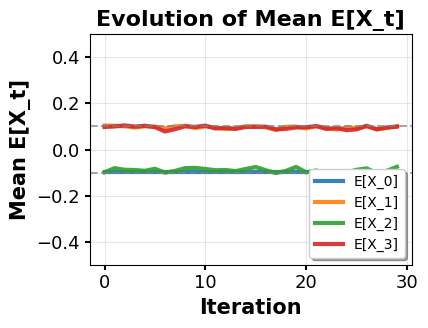

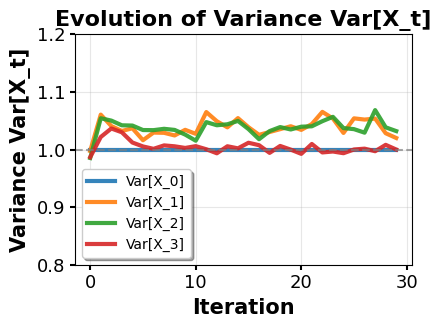

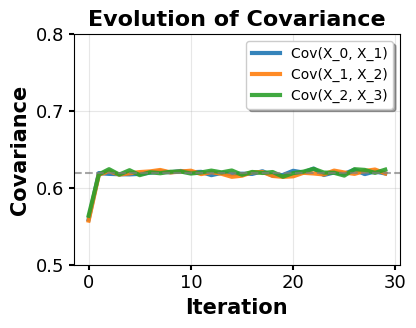

Publication-ready graphs saved as:
- mean_evolution.png
- variance_evolution.png
- covariance_evolution.png


In [25]:
import matplotlib.pyplot as plt
import numpy as np

# Set style and global font sizes for publication
plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 16,
    'axes.labelsize': 15,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 10,
    'lines.linewidth': 3
})

# 1. Graph for Means E[X_t]
fig1, ax1 = plt.subplots(figsize=(4.5, 3.5))
for t in temps_cibles:
    ax1.plot(iterations, moyennes[t], '-', label=f'E[X_{t}]', alpha=0.9, linewidth=3)

# Add reference lines
ax1.axhline(y=-0.10, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)
ax1.axhline(y=0.10, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)

ax1.set_xlabel('Iteration', fontweight='bold', fontsize=15)
ax1.set_ylabel('Mean E[X_t]', fontweight='bold', fontsize=15)
ax1.set_title('Evolution of Mean E[X_t]', fontweight='bold', fontsize=16)
ax1.set_ylim(-0.5, 0.5)
ax1.legend(fontsize=10, frameon=True, fancybox=True, shadow=True, loc='lower right')
ax1.grid(True, alpha=0.3)
ax1.tick_params(axis='both', which='major', labelsize=13, width=1.5)
plt.tight_layout()
plt.savefig('mean_evolution.png', dpi=300, bbox_inches='tight')
plt.show()

# 2. Graph for Variances Var[X_t]
fig2, ax2 = plt.subplots(figsize=(4.5, 3.5))
for t in temps_cibles:
    ax2.plot(iterations, variances[t], '-', label=f'Var[X_{t}]', alpha=0.9, linewidth=3)

# Add reference line
ax2.axhline(y=1.0, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)

ax2.set_xlabel('Iteration', fontweight='bold', fontsize=15)
ax2.set_ylabel('Variance Var[X_t]', fontweight='bold', fontsize=15)
ax2.set_title('Evolution of Variance Var[X_t]', fontweight='bold', fontsize=16)
ax2.set_ylim(0.8, 1.2)
ax2.legend(fontsize=10, frameon=True, fancybox=True, shadow=True)
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='both', which='major', labelsize=13, width=1.5)
plt.tight_layout()
plt.savefig('variance_evolution.png', dpi=300, bbox_inches='tight')
plt.show()

# 3. Graph for Covariances Cov(X_t, X_{t+1})
fig3, ax3 = plt.subplots(figsize=(4.5, 3.5))
for key in covariances.keys():
    # Convert key format for better display
    t1, t2 = key.split('_')
    label = f'Cov(X_{t1}, X_{t2})'
    ax3.plot(iterations, covariances[key], '-', label=label, alpha=0.9, linewidth=3)

# Add reference line
ax3.axhline(y=0.62, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)

ax3.set_xlabel('Iteration', fontweight='bold', fontsize=15)
ax3.set_ylabel('Covariance', fontweight='bold', fontsize=15)
ax3.set_title('Evolution of Covariance', fontweight='bold', fontsize=16)
ax3.set_ylim(0.5, 0.8)
ax3.legend(fontsize=10, frameon=True, fancybox=True, shadow=True)
ax3.grid(True, alpha=0.3)
ax3.tick_params(axis='both', which='major', labelsize=13, width=1.5)
plt.tight_layout()
plt.savefig('covariance_evolution.png', dpi=300, bbox_inches='tight')
plt.show()

print("Publication-ready graphs saved as:")
print("- mean_evolution.png")
print("- variance_evolution.png") 
print("- covariance_evolution.png")